# NLP Today Session 05: Fine-Tuning using LoRA

### Students:
- Zakaria SOUALAH MOHAMMED (zakaria.soualah-mohammed@universite-paris-saclay.fr)
- Wissam AMAR (wissam.amar@universite-paris-saclay.fr)

In [1]:
# %pip install torch==2.10.0+cu128 torchvision==0.25.0+cu128 torchaudio==2.10.0+cu128 --index-url https://download.pytorch.org/whl/cu128
# %pip install transformers datasets
# %pip install peft
# %pip install evaluate scikit-learn transformers[torch]
# %pip install "accelerate>=0.26.0"

# Prepare the dataset

In [2]:
from datasets import load_dataset

imdb = load_dataset("stanfordnlp/imdb")
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("bert-base-cased")


def tokenize_function(examples):
    return tokenizer(examples["text"], padding="max_length", truncation=True)


tokenized_datasets = imdb.map(tokenize_function, batched=True)


Dataset tokenization completed for all splits.

In [3]:
training_set = tokenized_datasets['train'].shuffle(42).select(range(5000))
shuffled_set =  tokenized_datasets['test'].shuffle(42)
validation_set  = shuffled_set.select(range(1000))
test_set = shuffled_set.select(range(1000, 2000))

## First method : Using the transformers library and pytorch


In [4]:
from transformers import BertTokenizer
from transformers import BertForSequenceClassification

## Fine-tuning the whole model

In [5]:
from transformers import set_seed

set_seed(42)
tokenizer = BertTokenizer.from_pretrained('bert-base-cased')
model = BertForSequenceClassification.from_pretrained('bert-base-cased', num_labels=2)

Pretrained BERT weights loaded successfully (199/199 tensors).

BertForSequenceClassification LOAD REPORT from: bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [6]:
# Have a look to 

import copy
import json
from pathlib import Path
import torch
import numpy as np
from transformers import TrainingArguments, Trainer

if not torch.cuda.is_available():
    raise RuntimeError("CUDA is unavailable. Select the Lab5 CUDA kernel and restart it.")
print("GPU:", torch.cuda.get_device_name(0))

results = {}
histories = {}


def show_results(name):
    print(f"\n{name}")
    for metric, value in results[name].items():
        number = f"{value:,}" if metric == "Trainable parameters" else f"{value:.4f}"
        print(f"{metric}: {number}")


def run_experiment(name, trainer):
    total = sum(p.numel() for p in trainer.model.parameters())
    trainable = sum(p.numel() for p in trainer.model.parameters() if p.requires_grad)
    # BERT computes a mean loss and does not use num_items_in_batch.
    trainer.model_accepts_loss_kwargs = False
    torch.cuda.reset_peak_memory_stats()
    train_output = trainer.train()
    peak_memory = torch.cuda.max_memory_allocated() / 1024**3
    validation = trainer.evaluate()
    test = trainer.evaluate(test_set, metric_key_prefix="test")
    results[name] = {
        "Trainable parameters": trainable,
        "Trainable (%)": 100 * trainable / total,
        "Validation accuracy": validation["eval_accuracy"],
        "Test accuracy": test["test_accuracy"],
        "Test loss": test["test_loss"],
        "Training time (s)": train_output.metrics["train_runtime"],
        "Peak GPU memory (GiB)": peak_memory,
    }
    show_results(name)
    histories[name] = trainer.state.log_history.copy()
    Path("figures").mkdir(exist_ok=True)
    Path("figures/metrics.json").write_text(
        json.dumps({"results": results, "histories": histories}, indent=2),
        encoding="utf-8",
    )
    trainer.model.cpu()
    trainer.optimizer = None
    trainer.lr_scheduler = None
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return train_output


full_model = copy.deepcopy(model)
full_training_args = TrainingArguments(
    output_dir="test_full_finetuning",
    eval_strategy="steps",
    eval_steps=128,
    num_train_epochs=2,
    per_device_train_batch_size=8,
    gradient_accumulation_steps=1,
    per_device_eval_batch_size=4,
    fp16=True,
    save_strategy="no",
    report_to="none",
)
full_trainer = Trainer(
    model=full_model,
    args=full_training_args,
    train_dataset=training_set,
    eval_dataset=validation_set,
    compute_metrics=lambda pred: {
        "accuracy": float(np.mean(pred.predictions.argmax(axis=-1) == pred.label_ids))
    },
)
full_train_output = run_experiment("Full fine-tuning", full_trainer)
del full_trainer, full_model
full_train_output

GPU: NVIDIA GeForce RTX 3060 Laptop GPU


Step,Training Loss,Validation Loss,Accuracy
128,No log,0.328058,0.861000
256,No log,0.399506,0.851000
384,No log,0.337621,0.873000
512,0.405352,0.357678,0.857000
640,0.405352,0.427038,0.893000
768,0.405352,0.525830,0.890000
896,0.405352,0.464492,0.891000
1024,0.211557,0.416266,0.898000
1152,0.211557,0.459477,0.898000



Full fine-tuning
Trainable parameters: 108,311,810
Trainable (%): 100.0000
Validation accuracy: 0.8970
Test accuracy: 0.9170
Test loss: 0.3815
Training time (s): 655.5293
Peak GPU memory (GiB): 3.0502


TrainOutput(global_step=1250, training_loss=0.27451622009277343, metrics={'train_runtime': 655.5293, 'train_samples_per_second': 15.255, 'train_steps_per_second': 1.907, 'total_flos': 2631110553600000.0, 'train_loss': 0.27451622009277343, 'epoch': 2.0})

## LoRA implementation

In [7]:
[k for k,v  in model.bert.named_parameters()]

['embeddings.word_embeddings.weight',
 'embeddings.position_embeddings.weight',
 'embeddings.token_type_embeddings.weight',
 'embeddings.LayerNorm.weight',
 'embeddings.LayerNorm.bias',
 'encoder.layer.0.attention.self.query.weight',
 'encoder.layer.0.attention.self.query.bias',
 'encoder.layer.0.attention.self.key.weight',
 'encoder.layer.0.attention.self.key.bias',
 'encoder.layer.0.attention.self.value.weight',
 'encoder.layer.0.attention.self.value.bias',
 'encoder.layer.0.attention.output.dense.weight',
 'encoder.layer.0.attention.output.dense.bias',
 'encoder.layer.0.attention.output.LayerNorm.weight',
 'encoder.layer.0.attention.output.LayerNorm.bias',
 'encoder.layer.0.intermediate.dense.weight',
 'encoder.layer.0.intermediate.dense.bias',
 'encoder.layer.0.output.dense.weight',
 'encoder.layer.0.output.dense.bias',
 'encoder.layer.0.output.LayerNorm.weight',
 'encoder.layer.0.output.LayerNorm.bias',
 'encoder.layer.1.attention.self.query.weight',
 'encoder.layer.1.attention.se

In [8]:
print(f"What is the model \n\n {model}")

What is the model 

 BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(28996, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNo

### Create the LoRA module

We will consider in this module the original linear, and the down and up projection

In [9]:
import torch 
import copy
from torch import nn

class LoRALinear(nn.Module):
  def __init__(
    self, in_dim: int, out_dim: int, rank: int
  ):
    super().__init__()
    self.linear = nn.Linear(in_dim, out_dim)
    self.linear.requires_grad_(False)
    self.lora_a = nn.Linear(in_dim, rank, bias=False)
    self.lora_b = nn.Linear(rank, out_dim, bias=False)
    nn.init.zeros_(self.lora_b.weight)

  def forward(self, x: torch.Tensor) -> torch.Tensor:
    return self.linear(x) + self.lora_b(self.lora_a(x))


### Create a function replacing linear by lora module
From the original Linear module return a LoRA module
* The linear of the LoRA linear must be initialised with pretrained weights

In [10]:


def linear_to_lora(linear):
    linear_weight = linear.weight.detach().clone()
    has_bias = linear.bias is not None
    if has_bias:
        linear_bias = linear.bias.detach().clone()
    output_size, input_size =  linear_weight.shape
    lora = LoRALinear(input_size, output_size, rank=8).to(
        device=linear.weight.device, dtype=linear.weight.dtype
    )
    lora.linear.weight.data = linear_weight
    if has_bias:
        lora.linear.bias.data = linear_bias
    else:
        lora.linear.bias = None
    return lora
    


We now replace the target linear by the LoRALinear described above

In [11]:
lora_model = copy.deepcopy(model)
lora_parameters = []
for block in lora_model.bert.encoder.layer:
    attention = block.attention.self
    for name in ("query", "key", "value"):
        lora = linear_to_lora(getattr(attention, name))
        setattr(attention, name, lora)
        lora_parameters.extend(lora.lora_a.parameters())
        lora_parameters.extend(lora.lora_b.parameters())

In [12]:
print(f"What is the model modified with LoRA: \n\n {lora_model}")


What is the model modified with LoRA: 

 BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(28996, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): LoRALinear(
                (linear): Linear(in_features=768, out_features=768, bias=True)
                (lora_a): Linear(in_features=768, out_features=8, bias=False)
                (lora_b): Linear(in_features=8, out_features=768, bias=False)
              )
              (key): LoRALinear(
                (linear): Linear(in_features=768, out_features=768, bias=True)
                (lora_a):

### Defining module requiring grad

In [13]:
for k,v  in lora_model.bert.named_parameters():
    print(k)
    if ('lora' in k):
        v.requires_grad = True
    else:
        v.requires_grad = False

embeddings.word_embeddings.weight
embeddings.position_embeddings.weight
embeddings.token_type_embeddings.weight
embeddings.LayerNorm.weight
embeddings.LayerNorm.bias
encoder.layer.0.attention.self.query.linear.weight
encoder.layer.0.attention.self.query.linear.bias
encoder.layer.0.attention.self.query.lora_a.weight
encoder.layer.0.attention.self.query.lora_b.weight
encoder.layer.0.attention.self.key.linear.weight
encoder.layer.0.attention.self.key.linear.bias
encoder.layer.0.attention.self.key.lora_a.weight
encoder.layer.0.attention.self.key.lora_b.weight
encoder.layer.0.attention.self.value.linear.weight
encoder.layer.0.attention.self.value.linear.bias
encoder.layer.0.attention.self.value.lora_a.weight
encoder.layer.0.attention.self.value.lora_b.weight
encoder.layer.0.attention.output.dense.weight
encoder.layer.0.attention.output.dense.bias
encoder.layer.0.attention.output.LayerNorm.weight
encoder.layer.0.attention.output.LayerNorm.bias
encoder.layer.0.intermediate.dense.weight
encode

## Using transformers Trainer to fine-tune with LoRA 

In [14]:
import numpy as np
import evaluate

metric = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return metric.compute(predictions=predictions, references=labels)

In [15]:
from transformers import TrainingArguments, Trainer

training_args = TrainingArguments(output_dir="test_custom_lora", 
                                  eval_strategy="steps",
                                  eval_steps= 128,
                                  num_train_epochs=2,
                                  per_device_train_batch_size=8,
                                  gradient_accumulation_steps=1,
                                  per_device_eval_batch_size=4,
                                  fp16=True,
                                  save_strategy="no",
                                  report_to="none",)
trainer = Trainer(
    model=lora_model,
    args=training_args,
    train_dataset= training_set,
    eval_dataset=validation_set,
    compute_metrics=compute_metrics,
)


In [16]:
custom_train_output = run_experiment("Custom LoRA", trainer)
custom_train_output

Step,Training Loss,Validation Loss,Accuracy
128,No log,0.672741,0.623000
256,No log,0.633190,0.690000
384,No log,0.540868,0.742000
512,0.620577,0.402039,0.826000
640,0.620577,0.350127,0.861000
768,0.620577,0.342164,0.861000
896,0.620577,0.331996,0.860000
1024,0.355210,0.331572,0.861000
1152,0.355210,0.332715,0.865000



Custom LoRA
Trainable parameters: 443,906
Trainable (%): 0.4082
Validation accuracy: 0.8680
Test accuracy: 0.8830
Test loss: 0.2983
Training time (s): 574.9424
Peak GPU memory (GiB): 1.8837


TrainOutput(global_step=1250, training_loss=0.4526288330078125, metrics={'train_runtime': 574.9424, 'train_samples_per_second': 17.393, 'train_steps_per_second': 2.174, 'total_flos': 2644700098560000.0, 'train_loss': 0.4526288330078125, 'epoch': 2.0})

## Using PEFT library to fine-tune with LoRA 

In [17]:
from peft import LoraConfig, TaskType,  get_peft_model

lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS, r=1, lora_alpha=1, lora_dropout=0.1
)

set_seed(42)
model = BertForSequenceClassification.from_pretrained(
    'bert-base-cased', 
    num_labels=2
)
peft_model = get_peft_model(model, lora_config)

Pretrained BERT weights loaded successfully (199/199 tensors).

BertForSequenceClassification LOAD REPORT from: bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [18]:
peft_model.print_trainable_parameters()

trainable params: 38,402 || all params: 108,350,212 || trainable%: 0.0354


In [19]:
from transformers import TrainingArguments, Trainer

training_args = TrainingArguments(output_dir="test_peft_lora", 
                                  eval_strategy="steps",
                                  eval_steps= 128,
                                  num_train_epochs=2,
                                  per_device_train_batch_size=8,
                                  gradient_accumulation_steps=1,
                                  per_device_eval_batch_size=4,
                                  fp16=True,
                                  label_names=["labels"],
                                  save_strategy="no",
                                  report_to="none",)
trainer = Trainer(
    model=peft_model,
    args=training_args,
    train_dataset= training_set,
    eval_dataset=validation_set,
    compute_metrics=compute_metrics,
)

In [20]:
peft_train_output = run_experiment("PEFT LoRA", trainer)
peft_train_output

Step,Training Loss,Validation Loss,Accuracy
128,No log,0.679384,0.603000
256,No log,0.672497,0.641000
384,No log,0.662968,0.648000
512,0.681851,0.651735,0.659000
640,0.681851,0.648924,0.625000
768,0.681851,0.626135,0.678000
896,0.681851,0.617386,0.673000
1024,0.650985,0.611206,0.691000
1152,0.650985,0.606908,0.695000



PEFT LoRA
Trainable parameters: 38,402
Trainable (%): 0.0354
Validation accuracy: 0.6950
Test accuracy: 0.6920
Test loss: 0.6094
Training time (s): 582.7972
Peak GPU memory (GiB): 1.8547


TrainOutput(global_step=1250, training_loss=0.6600603149414063, metrics={'train_runtime': 582.7972, 'train_samples_per_second': 17.159, 'train_steps_per_second': 2.145, 'total_flos': 2632290263040000.0, 'train_loss': 0.6600603149414063, 'epoch': 2.0})

## Compare the results of the different approaches

In [6]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display

figure_dir = Path("figures")
saved_metrics = json.loads((figure_dir / "metrics.json").read_text(encoding="utf-8"))
results = saved_metrics["results"]
histories = saved_metrics["histories"]

comparison = pd.DataFrame.from_dict(results, orient="index")
comparison.index.name = "Approach"
display(comparison.round(4))


,Trainable parameters,Trainable (%),Validation accuracy,Test accuracy,Test loss,Training time (s),Peak GPU memory (GiB)
Approach,,,,,,,
Full fine-tuning,108311810,100.0000,0.897,0.917,0.3815,655.5293,3.0502
Custom LoRA,443906,0.4082,0.868,0.883,0.2983,574.9424,1.8837
PEFT LoRA,38402,0.0354,0.695,0.692,0.6094,582.7972,1.8547


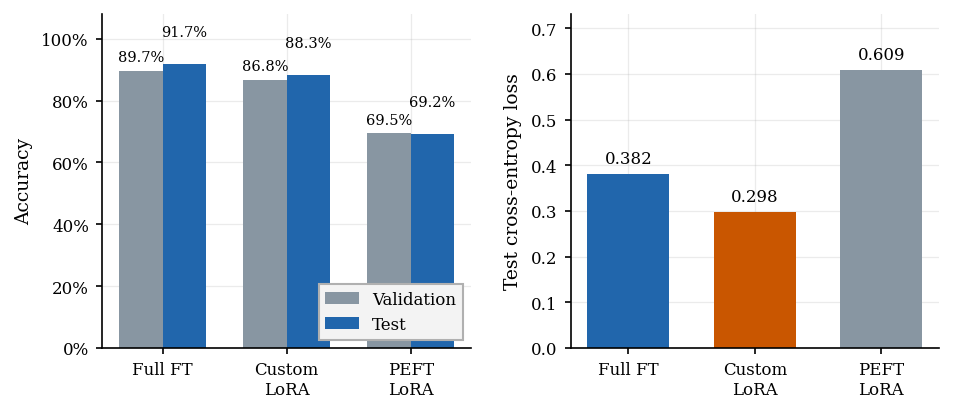

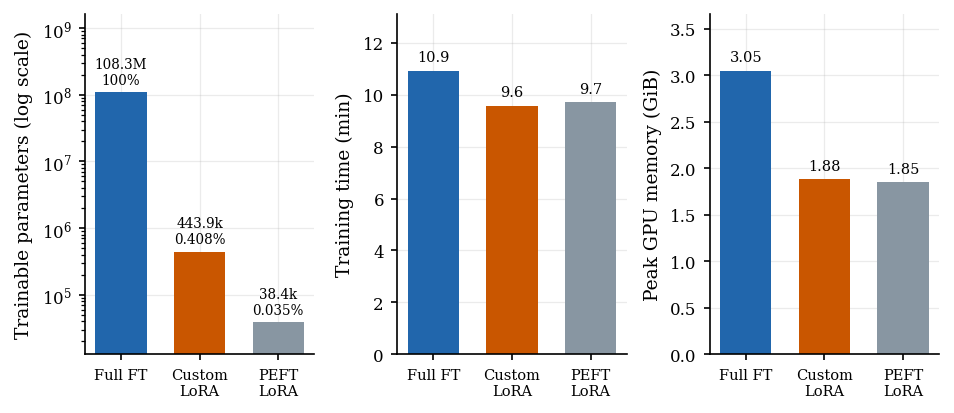

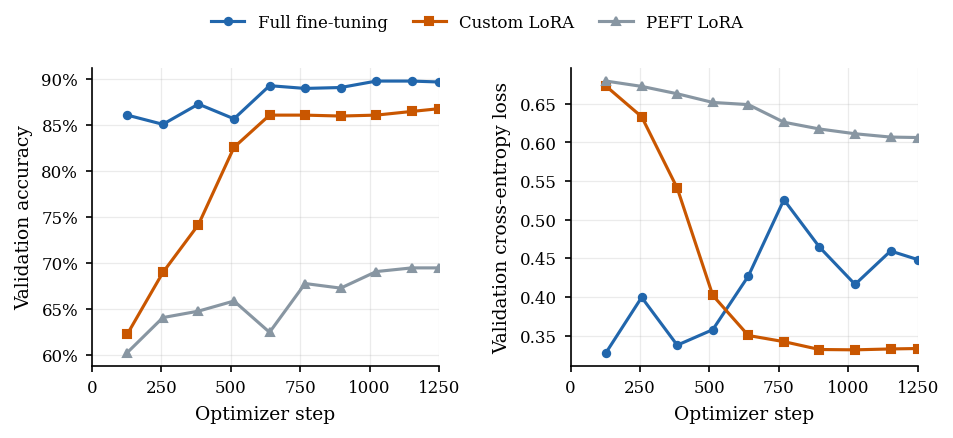

In [7]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif"],
    "font.size": 8,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "axes.linewidth": 0.8,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "mathtext.fontset": "dejavuserif",
    "pdf.fonttype": 42,
})

names = list(comparison.index)
labels = ["Full FT", "Custom\nLoRA", "PEFT\nLoRA"]
colors = ["#2166AC", "#C95600", "#8896A2"]
x = np.arange(len(names))


def clean_axes(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(length=3, width=0.8)
    ax.grid(color="#B0B0B0", linewidth=0.6, alpha=0.25)
    ax.set_axisbelow(True)


def save_figure(fig, name):
    fig.savefig(figure_dir / f"{name}.png", bbox_inches="tight")
    fig.savefig(figure_dir / f"{name}.pdf", bbox_inches="tight")
    plt.show()


fig, axes = plt.subplots(1, 2, figsize=(6.4, 2.8))
width = 0.35
for offset, column, color, label in [
    (-width / 2, "Validation accuracy", "#8896A2", "Validation"),
    (width / 2, "Test accuracy", "#2166AC", "Test"),
]:
    bars = axes[0].bar(x + offset, comparison[column], width,
                       color=color, label=label)
    axes[0].bar_label(bars, labels=[f"{v:.1%}" for v in comparison[column]],
                      padding=12 if label == "Test" else 3, fontsize=7)
axes[0].set_xticks(x, labels)
axes[0].set_ylim(0, 1.08)
axes[0].yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[0].set_ylabel("Accuracy")
axes[0].legend(loc="lower right", frameon=True,
               facecolor="#F3F3F3", edgecolor="#B0B0B0",
               framealpha=1, fancybox=False)

bars = axes[1].bar(x, comparison["Test loss"], color=colors, width=0.65)
axes[1].bar_label(bars, fmt="%.3f", padding=3, fontsize=8)
axes[1].set_xticks(x, labels)
axes[1].set_ylabel("Test cross-entropy loss")
axes[1].set_ylim(0, comparison["Test loss"].max() * 1.2)
for ax in axes:
    clean_axes(ax)
fig.tight_layout(w_pad=2)
save_figure(fig, "performance")

fig, axes = plt.subplots(1, 3, figsize=(6.4, 2.8))
axes[0].bar(x, comparison["Trainable parameters"], color=colors, width=0.65)
axes[0].set_yscale("log")
axes[0].set_ylabel("Trainable parameters (log scale)")
axes[0].set_ylim(comparison["Trainable parameters"].min() / 3,
                 comparison["Trainable parameters"].max() * 15)
for i, name in enumerate(names):
    count = comparison.loc[name, "Trainable parameters"]
    percentage = comparison.loc[name, "Trainable (%)"]
    short_count = f"{count / 1e6:.1f}M" if count >= 1e6 else f"{count / 1e3:.1f}k"
    percent = f"{percentage:.0f}%" if percentage == 100 else f"{percentage:.3f}%"
    axes[0].annotate(f"{short_count}\n{percent}", (i, count),
                     xytext=(0, 4), textcoords="offset points",
                     ha="center", fontsize=6.5)

minutes = comparison["Training time (s)"] / 60
bars = axes[1].bar(x, minutes, color=colors, width=0.65)
axes[1].bar_label(bars, fmt="%.1f", padding=3, fontsize=7)
axes[1].set_ylabel("Training time (min)")
axes[1].set_ylim(0, minutes.max() * 1.2)

memory = comparison["Peak GPU memory (GiB)"]
bars = axes[2].bar(x, memory, color=colors, width=0.65)
axes[2].bar_label(bars, fmt="%.2f", padding=3, fontsize=7)
axes[2].set_ylabel("Peak GPU memory (GiB)")
axes[2].set_ylim(0, memory.max() * 1.2)
for ax in axes:
    ax.set_xticks(x, labels, fontsize=7)
    clean_axes(ax)
fig.tight_layout(w_pad=1)
save_figure(fig, "training_cost")

fig, axes = plt.subplots(1, 2, figsize=(6.4, 2.9))
for name, color, marker in zip(names, colors, ["o", "s", "^"]):
    validation = [entry for entry in histories[name] if "eval_accuracy" in entry]
    steps = [entry["step"] for entry in validation]
    axes[0].plot(steps, [entry["eval_accuracy"] for entry in validation],
                 marker=marker, markersize=3.5, linewidth=1.5,
                 color=color, label=name)
    axes[1].plot(steps, [entry["eval_loss"] for entry in validation],
                 marker=marker, markersize=3.5, linewidth=1.5,
                 color=color, label=name)
axes[0].set_ylabel("Validation accuracy")
axes[0].yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[1].set_ylabel("Validation cross-entropy loss")
for ax in axes:
    ax.set_xlabel("Optimizer step")
    ax.set_xlim(0, 1250)
    ax.set_xticks([0, 250, 500, 750, 1000, 1250])
    clean_axes(ax)
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="upper center", ncol=3,
           frameon=False, handlelength=2, columnspacing=1.5)
fig.tight_layout(rect=(0, 0, 1, 0.9), w_pad=2)
save_figure(fig, "learning_curves")


### Discussion

Full fine-tuning gives the highest test accuracy in this run: **91.7%**, compared with **88.3%** for custom LoRA and **69.2%** for PEFT LoRA. The gap between full fine-tuning and custom LoRA is 3.4 percentage points. However, custom LoRA has a lower test cross-entropy loss (0.298 versus 0.382). The first figure shows why it is useful to keep both metrics: accuracy counts correct labels, while log loss also penalizes confident mistakes. A model can get more labels right and still have a worse log loss.

The parameter counts differ much more than the runtimes. Full fine-tuning updates **108,311,810** parameters, custom LoRA **443,906** (0.408% of its model), and PEFT **38,402** (0.035%). Training took **10.9**, **9.6**, and **9.7 minutes**, respectively, including validation during training. Peak allocated GPU memory was **3.05**, **1.88**, and **1.85 GiB**. Custom LoRA therefore used 38.2% less peak memory and 12.3% less training time than full fine-tuning. Freezing weights removes their gradients and optimizer states, but BERT still performs its forward pass and gradients still propagate through the layers between adapters. This explains why training hundreds of times fewer parameters does not produce the same reduction in runtime.

The learning curves show that full fine-tuning adapts much earlier, while the two LoRA models improve more gradually. Full fine-tuning's validation accuracy eventually levels off, and its validation loss fluctuates rather than falling consistently. Custom LoRA's validation loss generally decreases as its accuracy rises. The rank-1 PEFT run learns more slowly and remains below the other methods within the two-epoch budget. These curves help distinguish early convergence from the final scores in the first figure.

The two LoRA configurations are not equivalent. Custom LoRA uses rank 8 on query, key and value in all 12 attention layers, with no adapter dropout or extra scaling. PEFT uses rank 1 on query and value, dropout 0.1 and scaling $\alpha/r = 1$. This gives 442,368 custom adapter parameters versus 36,864 PEFT adapter parameters, a factor of 12; both also train the 1,538-parameter classifier. The accuracy gap therefore does not establish that manual LoRA is better than the PEFT library. A direct implementation comparison would match rank, target layers, scaling and dropout. Using a common learning rate controls one variable, but does not establish the best learning rate for each method.

All runs use the same 5,000 training reviews, validation/test splits, seed 42, checkpoint, batch size of 8 and two training epochs, with mixed precision on the RTX 3060. The test scores use 1,000 held-out reviews and were measured after training. GPU memory comes from PyTorch's allocator and excludes the CUDA context and other applications. Under these settings, full fine-tuning gives the best accuracy, while custom LoRA offers a smaller memory footprint with a modest accuracy drop. We would repeat the experiments with several seeds before treating small differences as reliable. LoRA's task-specific storage savings also require saving only the adapters and classifier; a full custom-model checkpoint would still contain the frozen BERT weights.
